# Línea de ensamble: cinco supervisores locales y su programa para OpenPLC

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_assembly_line_openplc.ipynb)

Una cinta trae tapas y otra trae bases. Cada pieza se detiene en un posicionador, que la sujeta
con una pinza (*clamp*). Un *pick & place* de dos ejes baja ($z$), toma la tapa, la lleva ($x$)
sobre la base sujeta y la suelta. Después se libera la base y la cuchilla de tope de la cinta de
bases deja salir la pieza ensamblada. La escena es la de ensamble de Factory I/O
(`Assembler_line.factoryio` del proyecto TCT_Proyect).

Este notebook es la versión DESlab del script `Assembly_line.py` de TCT_Proyect, que usaba TCT:
tiene los mismos componentes, especificaciones y mapa de señales, definidos directamente con `fsa`
y solo con los autolazos que hacen falta. Se sintetizan cinco supervisores locales y
`generate_ST_OPENPLC` genera el programa en texto estructurado (ST) para OpenPLC. Los supervisores
tienen el mismo comportamiento que los que calculaba TCT y el programa es igual, línea por línea,
al `Assembly_line.st` que generaba TCT_Proyect, salvo el nombre del programa (`supcon` en lugar de
`tesis0`).

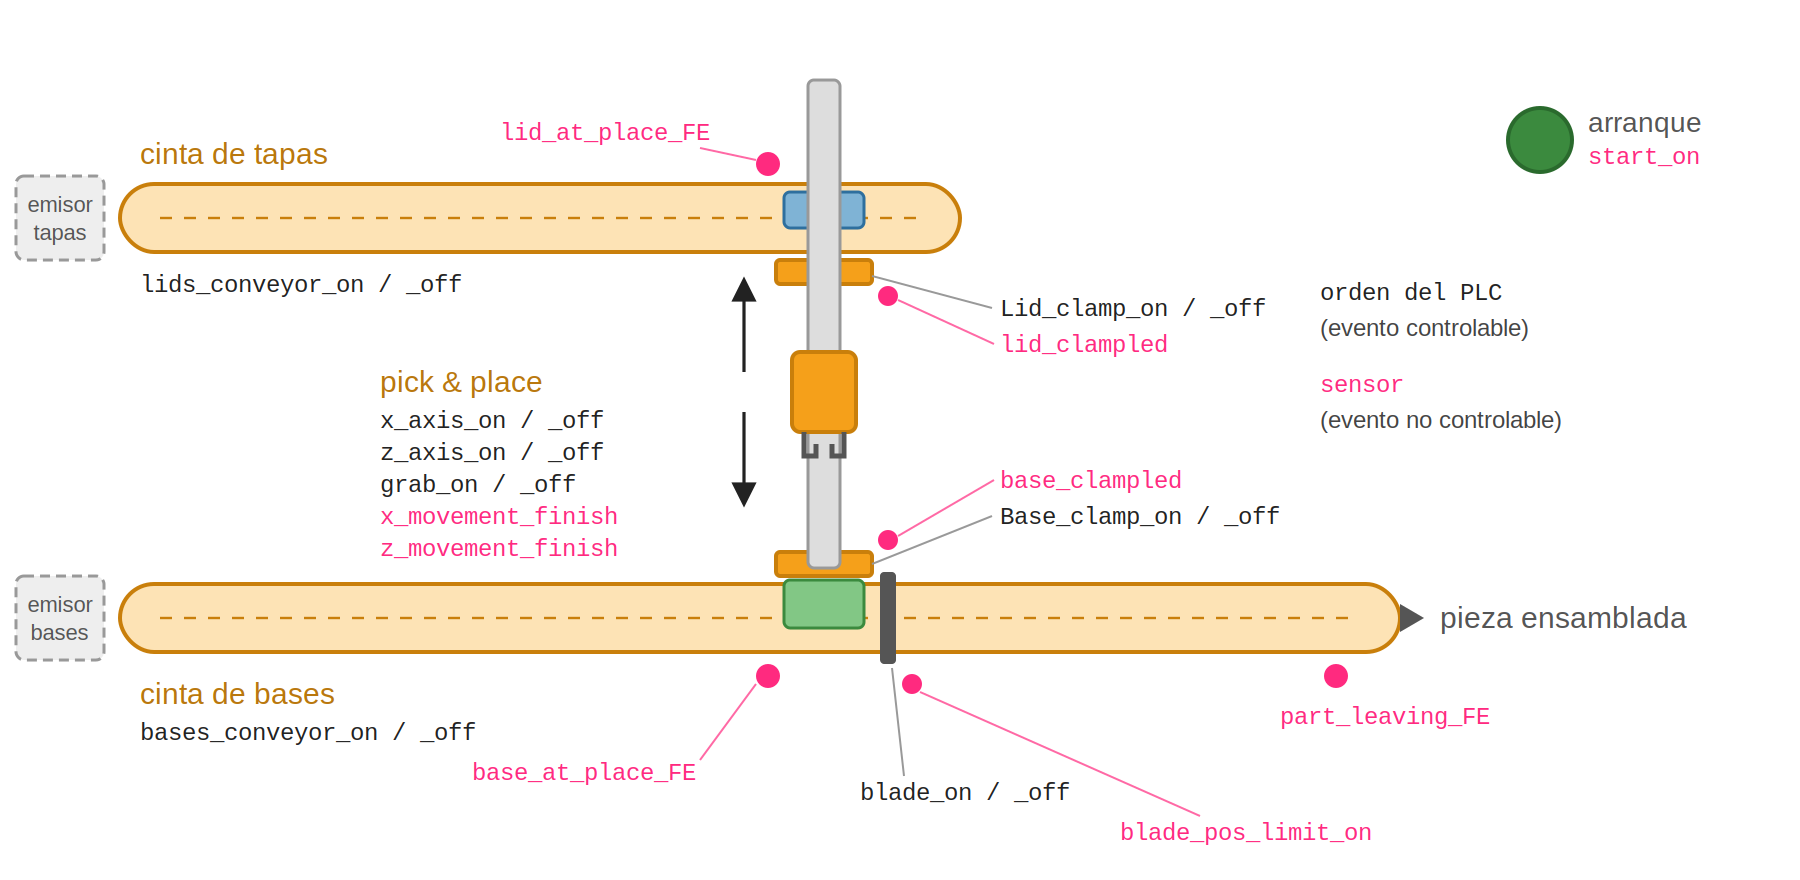

In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

In [2]:
from deslab import *

## 1. Eventos

Los eventos controlables son las órdenes del PLC a los actuadores; los no controlables son los
sensores y el pulsador de arranque. Se conservan los nombres del script original (incluido
`lid-clampled`), con guiones en lugar de `_`: DESlab dibuja lo que sigue a `_` como subíndice. El
sufijo `-FE` indica que el evento es el flanco de bajada del sensor.

| Componente | Órdenes (controlables) | Sensores (no controlables) |
|---|---|---|
| cinta de tapas | `lids-conveyor-on`, `lids-conveyor-off` | `lid-at-place-FE` (tapa en posición) |
| pinza de tapas | `Lid-clamp-on`, `Lid-clamp-off` | `lid-clampled` (tapa sujeta) |
| pick & place | `z-axis-on`, `z-axis-off`, `x-axis-on`, `x-axis-off`, `grab-on`, `grab-off` | `z-movement-finish`, `x-movement-finish` |
| cinta de bases | `bases-conveyor-on`, `bases-conveyor-off` | `base-at-place-FE` (base en posición) |
| pinza de bases | `Base-clamp-on`, `Base-clamp-off` | `base-clampled` (base sujeta) |
| cuchilla de tope | `blade-on`, `blade-off` | `blade-pos-limit-on` (cuchilla al límite), `part-leaving-FE` (pieza saliendo) |
| tablero | | `start-on` (pulsador de arranque) |

Las listas siguen el orden en que el script original declara los eventos; ese orden se usa al
final para numerar los estados como lo hacía TCT.

In [3]:
ORDENES = ['lids-conveyor-on', 'lids-conveyor-off', 'Lid-clamp-on', 'Lid-clamp-off',
           'grab-on', 'grab-off', 'z-axis-on', 'z-axis-off', 'x-axis-on', 'x-axis-off',
           'bases-conveyor-on', 'bases-conveyor-off', 'Base-clamp-on', 'Base-clamp-off',
           'blade-on', 'blade-off']
SENSORES = ['start-on', 'lid-clampled', 'lid-at-place-FE', 'z-movement-finish',
            'x-movement-finish', 'base-clampled', 'base-at-place-FE', 'blade-pos-limit-on',
            'part-leaving-FE']

## 2. Componentes de la planta

Cada componente se define con `fsa`: estados $0, \dots, n-1$, estado inicial 0, todos los estados
marcados y sus órdenes como eventos controlables (`Sigcon`). Las cintas, las pinzas, la pinza del
pick & place (*grab*) y la cuchilla tienen dos estados (apagado y encendido). Los ejes $z$ y $x$
tienen cuatro: la orden de mover, el fin del movimiento, la orden de volver y el fin del
movimiento de vuelta.

**Sensores compartidos.** Un sensor que usa una especificación tiene que estar en el alfabeto de la
planta local de su supervisor (sección 4), como evento no controlable. Si no está, la planta no lo
genera y el supervisor nunca lo deja ocurrir. Los sensores que no forman parte de la dinámica de un
componente se agregan como autolazos en todos los estados de un componente de esa planta: la planta
no restringe cuándo llegan. Hacen falta ocho:

| Componente | Autolazos de | Los usan |
|---|---|---|
| cinta de tapas | `start-on`, `lid-at-place-FE` | `start` y `buffer_lid` ($SUP_1$) |
| pinza de tapas | `lid-clampled` | `Lid_clamp_REQ` ($SUP_1$) y `buffer_arm` ($SUP_2$) |
| cinta de bases | `start-on`, `base-at-place-FE` | `start_2` y `buffer_base` ($SUP_4$) |
| pinza de bases | `base-clampled` | `complete_piece` ($SUP_3$) y `Base_clamp_REQ` ($SUP_4$) |
| cuchilla | `blade-pos-limit-on`, `part-leaving-FE` | `leave` ($SUP_5$) |

El script de TCT ponía además `lid_at_place_FE` en la pinza de tapas y `base_at_place_FE` en la
pinza de bases. No hacen falta: las cintas ya los llevan a las plantas de $SUP_1$ y $SUP_4$, y las
demás especificaciones no los usan.

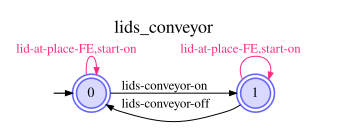

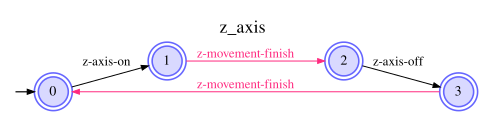

In [4]:
# los autolazos son los sensores que cada componente lleva a su planta
Lids_conveyor = fsa([0, 1], ['lids-conveyor-on', 'lids-conveyor-off', 'start-on', 'lid-at-place-FE'],
                    [(0, 'lids-conveyor-on', 1), (1, 'lids-conveyor-off', 0),
                     (0, 'start-on', 0), (1, 'start-on', 1),
                     (0, 'lid-at-place-FE', 0), (1, 'lid-at-place-FE', 1)],
                    [0], [0, 1], Sigcon=['lids-conveyor-on', 'lids-conveyor-off'], name='lids_conveyor')
Lid_clamp = fsa([0, 1], ['Lid-clamp-on', 'Lid-clamp-off', 'lid-clampled'],
                [(0, 'Lid-clamp-on', 1), (1, 'Lid-clamp-off', 0),
                 (0, 'lid-clampled', 0), (1, 'lid-clampled', 1)],
                [0], [0, 1], Sigcon=['Lid-clamp-on', 'Lid-clamp-off'], name='Lid_clamp')
Grab = fsa([0, 1], ['grab-on', 'grab-off'],
           [(0, 'grab-on', 1), (1, 'grab-off', 0)],
           [0], [0, 1], Sigcon=['grab-on', 'grab-off'], name='grab')
z_axis = fsa([0, 1, 2, 3], ['z-axis-on', 'z-movement-finish', 'z-axis-off'],
             [(0, 'z-axis-on', 1), (1, 'z-movement-finish', 2), (2, 'z-axis-off', 3),
              (3, 'z-movement-finish', 0)],
             [0], [0, 1, 2, 3], Sigcon=['z-axis-on', 'z-axis-off'], name='z_axis')
x_axis = fsa([0, 1, 2, 3], ['x-axis-on', 'x-movement-finish', 'x-axis-off'],
             [(0, 'x-axis-on', 1), (1, 'x-movement-finish', 2), (2, 'x-axis-off', 3),
              (3, 'x-movement-finish', 0)],
             [0], [0, 1, 2, 3], Sigcon=['x-axis-on', 'x-axis-off'], name='x_axis')
Base_conveyor = fsa([0, 1], ['bases-conveyor-on', 'bases-conveyor-off', 'start-on', 'base-at-place-FE'],
                    [(0, 'bases-conveyor-on', 1), (1, 'bases-conveyor-off', 0),
                     (0, 'start-on', 0), (1, 'start-on', 1),
                     (0, 'base-at-place-FE', 0), (1, 'base-at-place-FE', 1)],
                    [0], [0, 1], Sigcon=['bases-conveyor-on', 'bases-conveyor-off'], name='Base_conveyor')
Base_clamp = fsa([0, 1], ['Base-clamp-on', 'Base-clamp-off', 'base-clampled'],
                 [(0, 'Base-clamp-on', 1), (1, 'Base-clamp-off', 0),
                  (0, 'base-clampled', 0), (1, 'base-clampled', 1)],
                 [0], [0, 1], Sigcon=['Base-clamp-on', 'Base-clamp-off'], name='Base_clamp')
Blade = fsa([0, 1], ['blade-on', 'blade-off', 'blade-pos-limit-on', 'part-leaving-FE'],
            [(0, 'blade-on', 1), (1, 'blade-off', 0),
             (0, 'blade-pos-limit-on', 0), (1, 'blade-pos-limit-on', 1),
             (0, 'part-leaving-FE', 0), (1, 'part-leaving-FE', 1)],
            [0], [0, 1], Sigcon=['blade-on', 'blade-off'], name='blade')
draw(Lids_conveyor, z_axis)

## 3. Especificaciones

| Especificación | Qué pide |
|---|---|
| `start`, `start_2` | las cintas solo arrancan después del pulsador de arranque |
| `buffer_lid` | cinta de tapas: encender, esperar la tapa en posición, apagar, sujetarla y soltarla |
| `Lid_clamp_REQ` | la pinza de tapas se suelta solo después de que el sensor confirme la sujeción |
| `buffer_arm` | secuencia del pick & place: con la tapa sujeta, bajar, tomarla, soltar la pinza, subir, ir a la base, bajar, soltarla, subir y volver |
| `buffer_base`, `Base_clamp_REQ` | lo mismo que `buffer_lid` y `Lid_clamp_REQ` para las bases |
| `complete_piece` | el pick & place va hacia la base y suelta la tapa solo con la base sujeta |
| `leave` | después de soltar la base, levantar la cuchilla, esperar que salga la pieza y bajarla |

Cada especificación se define con `fsa`: primero su secuencia y después los autolazos de sus
sensores. En todas solo el estado 0 es marcado, salvo en `start` y `start_2`, donde el estado
marcado es el 1 (ya se pulsó el arranque).

**Autolazos de los sensores.** Una especificación incluye un sensor para esperarlo en un estado.
En los demás estados, un sensor del alfabeto que no está definido queda prohibido, y como no es
controlable, si la planta puede generarlo ahí el supervisor tiene que evitar llegar a ese estado.
Por eso la especificación lleva un autolazo del sensor en cada estado donde no lo espera y la
planta puede generarlo: lo deja pasar sin cambiar de estado. Donde la planta no puede generarlo,
el autolazo sobra. En `buffer_arm`, los fines de movimiento de los ejes solo ocurren después de
la orden de mover que la propia especificación da, y por eso no llevan autolazos; el script de TCT
les ponía 26. En total quedan 43 autolazos y cada uno es necesario.

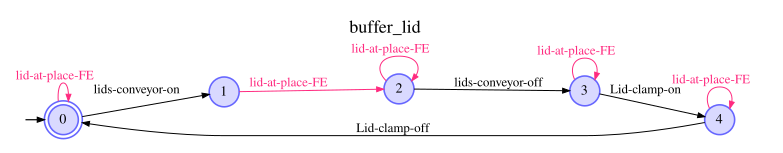

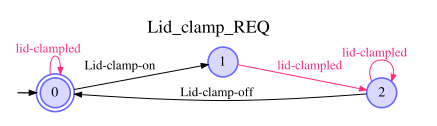

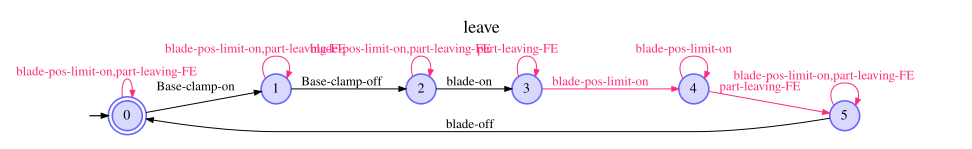

In [5]:
start = fsa([0, 1], ['start-on', 'lids-conveyor-on'],
            [(0, 'start-on', 1), (1, 'lids-conveyor-on', 1),
             (1, 'start-on', 1)],
            [0], [1], Sigcon=['lids-conveyor-on'], name='start')
buffer_lid = fsa([0, 1, 2, 3, 4],
                 ['lids-conveyor-on', 'lid-at-place-FE', 'lids-conveyor-off', 'Lid-clamp-on', 'Lid-clamp-off'],
                 [(0, 'lids-conveyor-on', 1), (1, 'lid-at-place-FE', 2), (2, 'lids-conveyor-off', 3),
                  (3, 'Lid-clamp-on', 4), (4, 'Lid-clamp-off', 0)]
                 + [(x, 'lid-at-place-FE', x) for x in (0, 2, 3, 4)],
                 [0], [0], Sigcon=['lids-conveyor-on', 'lids-conveyor-off', 'Lid-clamp-on', 'Lid-clamp-off'],
                 name='buffer_lid')
Lid_clamp_REQ = fsa([0, 1, 2], ['Lid-clamp-on', 'lid-clampled', 'Lid-clamp-off'],
                    [(0, 'Lid-clamp-on', 1), (1, 'lid-clampled', 2), (2, 'Lid-clamp-off', 0)]
                    + [(x, 'lid-clampled', x) for x in (0, 2)],
                    [0], [0], Sigcon=['Lid-clamp-on', 'Lid-clamp-off'], name='Lid_clamp_REQ')
buffer_arm = fsa(list(range(16)),
                 ['lid-clampled', 'z-axis-on', 'z-movement-finish', 'grab-on', 'Lid-clamp-off',
                  'z-axis-off', 'x-axis-on', 'x-movement-finish', 'grab-off', 'x-axis-off'],
                 [(0, 'lid-clampled', 1), (1, 'z-axis-on', 2), (2, 'z-movement-finish', 3),
                  (3, 'grab-on', 4), (4, 'Lid-clamp-off', 5), (5, 'z-axis-off', 6),
                  (6, 'z-movement-finish', 7), (7, 'x-axis-on', 8), (8, 'x-movement-finish', 9),
                  (9, 'z-axis-on', 10), (10, 'z-movement-finish', 11), (11, 'grab-off', 12),
                  (12, 'z-axis-off', 13), (13, 'z-movement-finish', 14), (14, 'x-axis-off', 15),
                  (15, 'x-movement-finish', 0)]
                 + [(x, 'lid-clampled', x) for x in range(1, 16)],
                 [0], [0], Sigcon=['z-axis-on', 'grab-on', 'Lid-clamp-off', 'z-axis-off', 'x-axis-on',
                                   'grab-off', 'x-axis-off'],
                 name='buffer_arm')
start_2 = fsa([0, 1], ['start-on', 'bases-conveyor-on'],
              [(0, 'start-on', 1), (1, 'bases-conveyor-on', 1),
               (1, 'start-on', 1)],
              [0], [1], Sigcon=['bases-conveyor-on'], name='start_2')
buffer_base = fsa([0, 1, 2, 3, 4],
                  ['bases-conveyor-on', 'base-at-place-FE', 'bases-conveyor-off', 'Base-clamp-on',
                   'Base-clamp-off'],
                  [(0, 'bases-conveyor-on', 1), (1, 'base-at-place-FE', 2), (2, 'bases-conveyor-off', 3),
                   (3, 'Base-clamp-on', 4), (4, 'Base-clamp-off', 0)]
                  + [(x, 'base-at-place-FE', x) for x in (0, 2, 3, 4)],
                  [0], [0], Sigcon=['bases-conveyor-on', 'bases-conveyor-off', 'Base-clamp-on',
                                    'Base-clamp-off'],
                  name='buffer_base')
Base_clamp_REQ = fsa([0, 1, 2], ['Base-clamp-on', 'base-clampled', 'Base-clamp-off'],
                     [(0, 'Base-clamp-on', 1), (1, 'base-clampled', 2), (2, 'Base-clamp-off', 0)]
                     + [(x, 'base-clampled', x) for x in (0, 2)],
                     [0], [0], Sigcon=['Base-clamp-on', 'Base-clamp-off'], name='Base_clamp_REQ')
complete_piece = fsa([0, 1, 2, 3, 4],
                     ['Base-clamp-on', 'base-clampled', 'x-axis-on', 'grab-off', 'Base-clamp-off'],
                     [(0, 'Base-clamp-on', 1), (1, 'base-clampled', 2), (2, 'x-axis-on', 3),
                      (3, 'grab-off', 4), (4, 'Base-clamp-off', 0)]
                     + [(x, 'base-clampled', x) for x in (0, 2, 3, 4)],
                     [0], [0], Sigcon=['Base-clamp-on', 'x-axis-on', 'grab-off', 'Base-clamp-off'],
                     name='complete_piece')
leave = fsa([0, 1, 2, 3, 4, 5],
            ['Base-clamp-on', 'Base-clamp-off', 'blade-on', 'blade-pos-limit-on', 'part-leaving-FE',
             'blade-off'],
            [(0, 'Base-clamp-on', 1), (1, 'Base-clamp-off', 2), (2, 'blade-on', 3),
             (3, 'blade-pos-limit-on', 4), (4, 'part-leaving-FE', 5), (5, 'blade-off', 0)]
            + [(x, 'blade-pos-limit-on', x) for x in (0, 1, 2, 4, 5)]
            + [(x, 'part-leaving-FE', x) for x in (0, 1, 2, 3, 5)],
            [0], [0], Sigcon=['Base-clamp-on', 'Base-clamp-off', 'blade-on', 'blade-off'], name='leave')
draw(buffer_lid, Lid_clamp_REQ, leave)

In [6]:
sin_autolazos = buffer_lid
for x in (0, 2, 3, 4):
    sin_autolazos = sin_autolazos.deletetransition((x, 'lid-at-place-FE', x))

G1 = Lids_conveyor // Lid_clamp
S = supcontrollable(G1 // sin_autolazos // Lid_clamp_REQ // start, G1)
print('estados de SUP1 si buffer_lid no tiene autolazos:', len(S))
assert len(S) == 0

estados de SUP1 si buffer_lid no tiene autolazos: 0


## 4. Supervisores locales

Cada supervisor controla solo los componentes que necesita su especificación:

| Supervisor | Planta local | Especificación |
|---|---|---|
| $SUP_1$ | cinta de tapas $\parallel$ pinza de tapas | `buffer_lid` $\parallel$ `Lid_clamp_REQ` $\parallel$ `start` |
| $SUP_2$ | pinza de tapas $\parallel$ grab $\parallel$ eje $z$ $\parallel$ eje $x$ | `buffer_arm` |
| $SUP_3$ | pinza de bases $\parallel$ grab $\parallel$ eje $x$ | `complete_piece` |
| $SUP_4$ | cinta de bases $\parallel$ pinza de bases | `buffer_base` $\parallel$ `Base_clamp_REQ` $\parallel$ `start_2` |
| $SUP_5$ | pinza de bases $\parallel$ cuchilla | `leave` |

El supervisor es `supcontrollable(G_k // E_k, G_k)`. En TCT la especificación se sincronizaba
también con `ALL` (todos los eventos de la planta); en DESlab no hace falta, porque la
composición paralela deja libres los eventos de la planta que la especificación no tiene.

$SUP_1$ y $SUP_4$ tienen los mismos estados y transiciones que los de TCT. $SUP_2$, $SUP_3$ y
$SUP_5$ tienen los mismos estados, pero un autolazo menos en cada estado: el de `lid-at-place-FE` o
el de `base-at-place-FE`, que en TCT les llegaba por las pinzas (109, 152 y 28 transiciones en
TCT). Ningún supervisor restringe ese sensor, así que el comportamiento es el mismo.

supervisor | estados planta | estados | transiciones
   SUP1    |              4 |       7 |           25
   SUP2    |             64 |      32 |           77
   SUP3    |             16 |      40 |          112
   SUP4    |              4 |       7 |           25
   SUP5    |              4 |       6 |           22


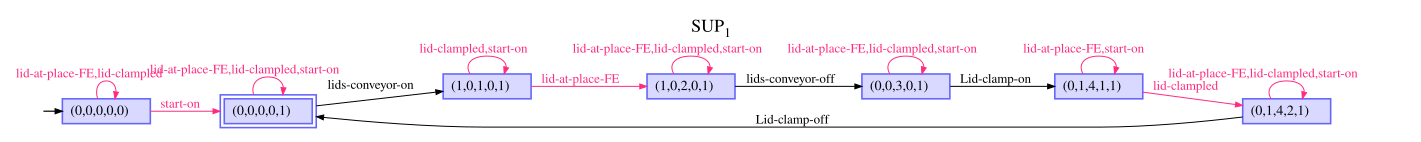

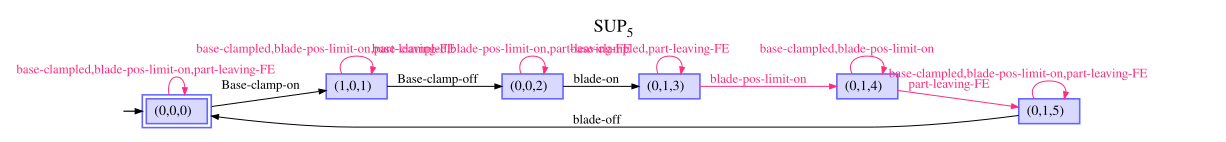

In [7]:
plantas = [Lids_conveyor // Lid_clamp,
           Lid_clamp // Grab // z_axis // x_axis,
           Base_clamp // Grab // x_axis,
           Base_conveyor // Base_clamp,
           Base_clamp // Blade]
especificaciones = [buffer_lid // Lid_clamp_REQ // start,
                    buffer_arm,
                    complete_piece,
                    buffer_base // Base_clamp_REQ // start_2,
                    leave]
supervisores = []
for k, (Gk, Ek) in enumerate(zip(plantas, especificaciones), 1):
    Sk = supcontrollable(Gk // Ek, Gk).setpar(name=f'$SUP_{k}$', style='rectangle')
    supervisores.append(Sk)

print('supervisor | estados planta | estados | transiciones')
for k, (Gk, Sk) in enumerate(zip(plantas, supervisores), 1):
    transiciones = sum(len(Sk.Gamma(x)) for x in Sk.X)
    print(f'   SUP{k}    | {len(Gk):14} | {len(Sk):7} | {transiciones:12}')
draw(supervisores[0], supervisores[4])

## 6. Mapa de señales

Es el mapa del script original. `Variable:ON:dirección` y `Variable:OFF` escriben 1 y 0 en una
salida (la dirección se declara una vez); `Variable:ON:%IX...` observa el nivel 1 de una entrada;
`FE_Nombre:Entrada:dirección` crea un detector de flanco de bajada (`F_TRIG`). Las claves son
los eventos, con guiones; las variables del PLC conservan `_` porque en ST un identificador no
puede tener guiones.

`Mask` copia en cada scan una entrada en otra salida: los interruptores `GD_IN_10` y `GD_IN_11`
encienden los emisores de bases y de tapas (`GD_OUT_12` y `GD_OUT_13`). `gen-base` y `gen-lid`
no son eventos de los supervisores; están en el mapa para declarar esas entradas.

In [8]:
actuators = {
    'lids-conveyor-on': 'GD_OUT_2:ON:%QX100.2', 'lids-conveyor-off': 'GD_OUT_2:OFF',
    'bases-conveyor-on': 'GD_OUT_3:ON:%QX100.3', 'bases-conveyor-off': 'GD_OUT_3:OFF',
    'Lid-clamp-on': 'GD_OUT_4:ON:%QX100.4', 'Lid-clamp-off': 'GD_OUT_4:OFF',
    'Base-clamp-on': 'GD_OUT_5:ON:%QX100.5', 'Base-clamp-off': 'GD_OUT_5:OFF',
    'z-axis-on': 'GD_OUT_6:ON:%QX100.6', 'z-axis-off': 'GD_OUT_6:OFF',
    'grab-on': 'GD_OUT_7:ON:%QX100.7', 'grab-off': 'GD_OUT_7:OFF',
    'x-axis-on': 'GD_OUT_8:ON:%QX101.0', 'x-axis-off': 'GD_OUT_8:OFF',
    'blade-on': 'GD_OUT_9:ON:%QX101.1', 'blade-off': 'GD_OUT_9:OFF',
    'start-on': 'GD_IN_15:ON:%IX100.15',
    'lid-at-place-FE': 'FE_LaP:GD_IN_2:%IX100.2',
    'lid-clampled': 'GD_IN_4:ON:%IX100.4',
    'base-at-place-FE': 'FE_BaP:GD_IN_3:%IX100.3',
    'part-leaving-FE': 'FE_PaL:GD_IN_9:%IX101.1',
    'base-clampled': 'GD_IN_5:ON:%IX100.5',
    'z-movement-finish': 'FE_Zag:GD_IN_6:%IX100.6',
    'x-movement-finish': 'FE_Xag:GD_IN_7:%IX100.7',
    'blade-pos-limit-on': 'GD_IN_8:ON:%IX101.0',
    'gen-base': 'GD_IN_10:ON:%IX102.5',
    'gen-lid': 'GD_IN_11:ON:%IX102.6',
}
Mask = {'GD_IN_10': [('GD_OUT_12', '%QX101.2')],
        'GD_IN_11': [('GD_OUT_13', '%QX101.3')]}

## 7. Generar el programa

TCT numeraba los eventos controlables con números impares y los no controlables con pares, en
el orden en que se declaraban. Con `event_order` en ese mismo orden, `generate_ST_OPENPLC` numera
los estados y escribe las ramas como el generador de TCT_Proyect, y el programa coincide con el
que se generaba con TCT.

El programa empieza en el primer scan (`initial="null"`); las cintas esperan el pulsador
`start-on`, que forma parte de las especificaciones.

In [9]:
from pathlib import Path

codigo = {e: 2 * k + 1 for k, e in enumerate(ORDENES)}
codigo.update({e: 2 * k for k, e in enumerate(SENSORES)})
orden_eventos = sorted(codigo, key=codigo.get)

carpeta = Path('ST_Generated')
st = generate_ST_OPENPLC(supervisores, plants=plantas, actuators=actuators,
                         namest='Assembly_line', Mask=Mask, output_dir=carpeta,
                         event_order=orden_eventos)
archivo = carpeta / 'Assembly_line.st'
assert archivo.read_text(encoding='utf-8') == st
assert '_C :' not in st                         # sin coordinadores
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))

programa guardado en ST_Generated/Assembly_line.st
líneas: 740


In [10]:
print(st)
# en Colab se descarga el archivo; en Jupyter queda un enlace
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(str(archivo)))

FUNCTION_BLOCK random_number
	VAR_INPUT
		IN : BOOL;
	END_VAR
	VAR
		M : BOOL;
		INIT : BOOL;
	END_VAR
	VAR_OUTPUT
		OUT : DINT;
	END_VAR

	IF INIT = 0 THEN
		{#include <stdio.h>}
		{#include <stdlib.h>}
		IN := 1;
	END_IF;
	IF M = 0 and IN = 1 THEN
		{SetFbVar(OUT,rand())}
	END_IF;
END_FUNCTION_BLOCK
PROGRAM supcon
	VAR
		random : random_number;
		random_num : DINT;
		state : ARRAY [0..5] OF DINT;
		slt1 : ARRAY [0..8] OF DINT;
		slt2 : ARRAY [0..15] OF DINT;
		GD_OUT_4_G : ARRAY [0..2] OF BOOL;
		GD_OUT_7_G : ARRAY [0..2] OF BOOL;
		GD_OUT_8_G : ARRAY [0..2] OF BOOL;
		GD_OUT_5_G : ARRAY [0..3] OF BOOL;
		FE_LaP : F_TRIG;
		FE_BaP : F_TRIG;
		FE_PaL : F_TRIG;
		FE_Zag : F_TRIG;
		FE_Xag : F_TRIG;
	END_VAR
	VAR
		GD_OUT_12 AT %QX101.2 : BOOL;
 		GD_OUT_13 AT %QX101.3 : BOOL;
 		GD_OUT_2 AT %QX100.2 : BOOL;
		GD_OUT_3 AT %QX100.3 : BOOL;
		GD_OUT_4 AT %QX100.4 : BOOL;
		GD_OUT_5 AT %QX100.5 : BOOL;
		GD_OUT_6 AT %QX100.6 : BOOL;
		GD_OUT_7 AT %QX100.7 : BOOL;
		GD_OUT_8 AT %QX101.0 : B

ST_Generated/Assembly_line.st

## 8. Validación y puesta en marcha

Los cinco supervisores tienen el mismo comportamiento que los de TCT: con los autolazos de
`lid-at-place-FE` y `base-at-place-FE` que les faltan, $SUP_2$, $SUP_3$ y $SUP_5$ tienen los mismos
estados y transiciones que los de TCT. El programa generado es idéntico al `Assembly_line.st` de
TCT_Proyect, salvo el nombre del programa (`supcon` en lugar de `tesis0`); la prueba `tests/test_openplc_notebooks.py` ejecuta las celdas de este notebook y
comprueba la huella SHA-256 de ese archivo con el nombre de TCT, y además que cada autolazo de los modelos es necesario.

Para llevarlo a OpenPLC, importe el archivo `.st`, compílelo y asigne las direcciones de la
escena. Con las cintas detenidas y los ejes en reposo, pulse el arranque y siga una pieza: tapa
en posición y sujeta, recorrido completo del pick & place, base sujeta, tapa colocada y salida
por la cuchilla.